In [1]:
import statistics
import numpy as np
import scipy.stats
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
import seaborn as sns
import statsmodels.api

### IMPORT DATA


In [2]:
bigFive = ['Extraversion', 'Agreeableness', 'Conscientiousness', 'Neuroticism', 'Openness']
judges = ['Judge 1', 'Judge 2', 'Judge 3', 'Judge 4', 'Judge 5', 'Judge 6', 'Judge 7', 'Judge 8', 'Judge 9', 'Judge 10', 'Judge 11']

#Function taking the judge number 01-11 to return their table of scores
def printJudge(judgeNo):
   # [640rows x 6 columns]
    # Columns: Clip_ID (0), Extraversion (1), Agreeableness (2), Conscientiousness (3), Neuroticism (4), Openness (5)
   return pd.read_csv(f'data/Personality_Scores/Score_0{judgeNo}.csv', delimiter=',')

# [640rows x 4 columns]
#  Columns: Clip_ID (0), Speaker_ID (1), Gender (2), Status (3)
metadata = pd.read_csv('data/metadata.csv')

# Data per Judge
judge1= np.array(printJudge('01'))
judge2= np.array(printJudge('02'))
judge3= np.array(printJudge('03'))
judge4= np.array(printJudge('04'))
judge5= np.array(printJudge('05'))
judge6= np.array(printJudge('06'))
judge7= np.array(printJudge('07'))
judge8= np.array(printJudge('08'))
judge9= np.array(printJudge('09'))
judge10= np.array(printJudge('10'))
judge11= np.array(printJudge('11'))


### DATA MANIPULATION

In [3]:
#ALL JUDGES OBSERVATIONS ONE TRAIT

#ALL OBSERVATIONS FOR ALL JUDGES TOGETHER IN A SINGLE 1D ARRAY
def allJudgesOneTrait(trait):
    total = judge1[:,trait]
    for i in range(1,11):
        if (i<9):
            x = '0' + str(i+1)
        else:
            x = str(i+1)
        total = np.concatenate([total, np.array(printJudge(x))[:,trait]])
    return total

# 11 x 640 array - ONE row per judge
def allJudgesOneTrait2D(trait):
    total = judge1[:,trait].tolist()
    for i in range(1,11):
        if (i<9):
            x = '0' + str(i+1)
        else:
            x = str(i+1)
        new = np.array(printJudge(x))[:,trait]
        total = np.vstack((total,new))
    return total


# np.array(allJudgesOneTrait2D(1)).shape

In [4]:
# ALL INFO FOR A JUDGE FOR ONE GENDER
# Connect Data  parameters --> F or M , judge1 etc.
def splitPerGender(gender, judgeNo):
    judgeData = judgeNo
    listOfGender = np.where(np.array(metadata)[:,2] == gender)[0]
    judgeGenderData = judgeData[listOfGender]
    return (judgeGenderData)

# F tests -- to see if the variance is equal or not - no evidence to reject that it is not equal.

# def f_test(group1, group2):
#    a = np.var(group1, ddof=1)
#    b = np.var(group2, ddof=1)
#    f= a/b
#    nun = group1.size-1
#    dun = group2.size-1
#    p_value = 1-scipy.stats.f.cdf(f, nun, dun)
#    return f, p_value


##### Ways to average the scores

In [5]:
#MEAN Scores per clip between judges - 640x5 scores 
def meanScoresPerClip():
    clipIDs = judge1[:,0]
    result = []
    allScores=[]
    for i in range(11):
        if (i<9):
            x = '0' + str(i+1)
        else:
            x = str(i+1)
        scores = np.array(np.array(printJudge(x))[:,1:])
        allScores.append(scores)
    allScores = np.stack(allScores, axis=0)
    meanScoresPerClip = np.mean(allScores, axis=0)
    result = np.column_stack((np.array(clipIDs), meanScoresPerClip))
    return result


In [6]:
#MEDIAN Scores per clip between judges - 640x5 scores
def medianScoresPerClip():
    clipIDs = judge1[:,0]
    result = []
    allScores=[]
    for i in range(11):
        if (i<9):
            x = '0' + str(i+1)
        else:
            x = str(i+1)
        scores = np.array(np.array(printJudge(x))[:,1:])
        allScores.append(scores)
    allScores = np.stack(allScores, axis=0)
    medianScoresPerClip = np.median(allScores, axis=0)
    medianScoresPerClip = medianScoresPerClip.astype(int)
    result = np.column_stack((np.array(clipIDs), medianScoresPerClip))
    return result

In [7]:
#MODE Scores per clip between judges
def calcMode(x):
    unique_elements, counts = np.unique(x, return_counts=True)
    mode_index = np.argmax(counts)
    return unique_elements[mode_index]

def modeScoresPerClip():
    clipIDs = judge1[:,0]
    result = []
    allScores=[]
    for i in range(11):
        if (i<9):
            x = '0' + str(i+1)
        else:
            x = str(i+1)
        scores = np.array(np.array(printJudge(x))[:,1:])
        allScores.append(scores)
    allScores = np.stack(allScores, axis=0)
    allScores = np.transpose(allScores, (1,2,0))
    mode_result = np.apply_along_axis(calcMode, axis=2, arr=allScores)
    result = np.column_stack((np.array(clipIDs), mode_result))
    print(result)


In [11]:
#Median Scores per clip between judges - ONE GENDER
def medianScoresPerClipGender(gender, no10):
    listOfGender = np.where(np.array(metadata)[:,2] == gender)[0]
    clipIDsForGender = judge1[:,0][listOfGender]
    result = []
    allScores=[]
    i = 0
    while (i<11):
        if ((no10==True) & (i == 9)):
            i = i + 1
        if (i<9):
            x = '0' + str(i+1)
        else:
            x = str(i+1)
        scores = np.array(np.array(printJudge(x))[:,1:][listOfGender])
        allScores.append(scores)
        i = i + 1
    allScores = np.stack(allScores, axis=0)
    meanScoresPerClip = np.median(allScores, axis=0)
    result = np.column_stack((np.array(clipIDsForGender), meanScoresPerClip))
    return result

## Distribution of data

In [10]:
#Box plot of mean data per clip for each trait
def plotDistributionBox():
    data = meanScoresPerClip()[:,1:]
    df = pd.DataFrame(data,columns=bigFive) 
    display(Markdown('## Box plot of mean data per clip for each trait'))
    plot2 = sns.catplot(kind='box', data=df)
    plot2.set_axis_labels("Big Five", "Scores")

In [12]:
# HISTOGRAMS FOR EACH TRAIT FOR DISTRIBUTION OF MEAN SCORES PER CLIP
def distributionHistograms():
    data = meanScoresPerClip()[:,1:]
    df = pd.DataFrame(data,columns=bigFive) 
    display(Markdown('## Distribution of the mean scores per clip for every trait'))
    for i in range(5):
        plot = sns.displot(data[:,i], kde=True)
        plot.set_axis_labels(bigFive[i], "Count")

## Pearsons Correlation Coefficient
* Measure of the linear relationship between two features 
    * Ratio of the covariance of x & y to the product of their standard deviation
    * takes pairs = each pair is an observation
    * -1 to 1
    * =1 --> perfect linear relationship
    * \>0 --> positive correlation
    * =0 --> no linear relationship
    * <0 --> negative correlation
    * =-1 --> perfect -ve linear relationship.
<br> <br>
* P VALUES 
    * Statistical Significance - the likelihood of the correlation being due to chance
    * p value under 0.05 is often considered enough to reject the null hypothesis.


In [20]:
#Show the correlation coefficient WITHOUT P VALUES between each trait between two judges
def corrPerTrait(judgeA, judgeB):
    listOfCoefficients = []
    i=1
    while i <6:
        listOfCoefficients.append(np.corrcoef(judgeA[:,i].tolist(), judgeB[:,i].tolist())[0:1][0][1])
        # listOfCoefficients.append(scripy.stats.pearsonr(judgeA[:,i].tolist(), judgeB[:,i].tolist()))
        i = i + 1
    return (listOfCoefficients)

# corrPerTrait(judge1,judge2)

Agreement between Judges for a specific trait:
- Only prints correlation coefficient & not p value
- Use scipy.stats.pearsonr instead of np.corrcoef

In [21]:
# For a specific trait (parameter -> 1-6) creates a list of all correlations between all 55 unique combinations of judges to 2 decimal places
def corrAllJudgesOneTrait(trait):
    listOfCoefficients = []
    listOfPairs = []
    # listOfPairsAndCorr = []
    for i in range(11):
        if (i<9):
            x = '0' + str(i+1)
        else:
            x = str(i+1)
        judgeA = np.array(printJudge(x))
        for j in range(i+1,11):
            # row = []
            if (j<9):
                y = '0' + str(j+1)
            else:
                y = str(j+1)
            judgeB = np.array(printJudge(y))
            # listOfPairs.append((i+1,j+1))
            # row.append(i+1)
            # row.append(j+1)
            # row.append(np.corrcoef(judgeA[:,trait].tolist(), judgeB[:,trait].tolist())[0:1][0][1])
            # listOfPairsAndCorr.append(row)
            listOfCoefficients.append(np.corrcoef(judgeA[:,trait].tolist(), judgeB[:,trait].tolist())[0:1][0][1])
    # print(listOfPairs)
    return (listOfCoefficients)
    # return listOfPairsAndCorr

Returns a list of [JudgeA, JudgeB, and then one by one the correlation coef for each trait] DOES NOT INCLUDE P VALUE

In [18]:
# Pearson
def corrAllJudgesAllTraits():
    listOfCoefficients = []
    listOfPairs = []
    listOfPairsAndCorr = []
    for i in range(11):
        if (i<9):
            x = '0' + str(i+1)
        else:
            x = str(i+1)
        judgeA = np.array(printJudge(x))
        for j in range(i+1,11):
            row = []
            if (j<9):
                y = '0' + str(j+1)
            else:
                y = str(j+1)
            judgeB = np.array(printJudge(y))
            # listOfPairs.append((i+1,j+1))
            row.append(i+1)
            row.append(j+1)
            for k in range(1,6):
                listOfCoefficients.append(np.corrcoef(judgeA[:,k].tolist(), judgeB[:,k].tolist())[0:1][0][1])
                row.append(np.corrcoef(judgeA[:,k].tolist(), judgeB[:,k].tolist())[0:1][0][1])
            listOfPairsAndCorr.append(row)
    # print(listOfPairs)
    # return (listOfCoefficients)
    return listOfPairsAndCorr

Returns a list of [JudgeA, JudgeB, at then one by one the correlation coef for each trait] INCLUDES P VALUE

In [23]:
# Pearson
def corrAllJudgesAllTraitsWITHP():
    listOfCoefficients = []
    listOfPairs = []
    listOfPairsAndCorr = []
    for i in range(11):
        if (i<9):
            x = '0' + str(i+1)
        else:
            x = str(i+1)
        judgeA = np.array(printJudge(x))
        for j in range(i+1,11):
            row = []
            if (j<9):
                y = '0' + str(j+1)
            else:
                y = str(j+1)
            judgeB = np.array(printJudge(y))
            # listOfPairs.append((i+1,j+1))
            row.append(i+1)
            row.append(j+1)
            for k in range(1,6):
                listOfCoefficients.append(scipy.stats.pearsonr(judgeA[:,k].tolist(), judgeB[:,k].tolist()))
                row.append(scipy.stats.pearsonr(judgeA[:,k].tolist(), judgeB[:,k].tolist()))
            listOfPairsAndCorr.append(row)
    # print(listOfPairs)
    # return (listOfCoefficients)
    return listOfPairsAndCorr

In [24]:
# Pearson
def medianOfCorrelationsBetweenJudges(trait):
    return (np.median(corrAllJudgesOneTrait(trait)))

def meanOfCorrelationsBetweenJudges(trait):
    return (np.mean(corrAllJudgesOneTrait(trait)))


### Agreement Between Judges for every trait

HISTOGRAMS OF Frequency against Correlation Coefficient between the 55 judge combinations for a specific trait


In [25]:
def histogramsPearsonPairsFrequency():
    fig, axs = plt.subplots(5, 1, figsize=(7, 30))
    axs = axs.flatten()
    for i in range(1,6):
        axs[i-1].hist(corrAllJudgesOneTrait(i), bins=90, range=(-0.25,0.5), color='blue', edgecolor='black', rwidth=0.8, label=f'All correlations between judges {bigFive[i-1]}')
        axs[i-1].set_title(f'Frequency against Correlation Coefficient between judges for {bigFive[i-1]}', fontsize=10)
        axs[i-1].set_xlabel('Correlation Coefficient between judges', fontsize=10)
        axs[i-1].set_ylabel('Frequency of a specific correlation', fontsize=10)
    # axs[5].axis('off')
    plt.tight_layout(pad=0.4, w_pad=0.5, h_pad=1.0)
    plt.figure()



TABLE OF ALL PEARSON CORRELATIONS AND CORRESPONDING P VALUES FOR EACH TRAIT FOR ALL 55 UNIQUE COMBINATIONS OF JUDGES

In [26]:
def PearsonTable():
    data_dict = corrAllJudgesAllTraitsWITHP()
    columns = np.concatenate((['JudgeA', 'JudgeB'],bigFive),axis=0)

    # creating a data frame object 
    dfPearson = pd.DataFrame(data_dict, columns=columns) 
    dfPearson.index = range(1, len(dfPearson) + 1)
    # df.table_title('hello')
    display(Markdown('## Pearson Correlations For each Trait in Coefficient, P-value pairs'))
    display(dfPearson)


In [27]:
# Table of Average MEAN pearson correlation per trait
def PearsonAverageTable():
    averagesPerTrait = []
    for trait in bigFive:      
        # averagesPerTrait.append(scipy.stats.mode(dfPearson[trait].tolist(),axis=0)[0][0])
        averagesPerTrait.append(dfPearson[trait].mean()) 

    dfAverages = pd.DataFrame(averagesPerTrait,columns=['Correlation Coefficient','P-value'])
    dfAverages.index = bigFive
    display(Markdown('## Average Pearson Correlation per Trait (Coefficient & P-value)'))
    display(dfAverages)
    # print(averagesPerTrait)

In [28]:
# Table of Average MODE pearson correlation per trait
def PearsonModeAverageTable():
    averagesPerTrait = []
    for trait in bigFive:      
        averagesPerTrait.append(scipy.stats.mode(dfPearson[trait].tolist(),axis=0)[0][0])
        # averagesPerTrait.append(dfPearson[trait].mean()) 

    dfAverages = pd.DataFrame(averagesPerTrait,columns=['Correlation Coefficient','P-value'])
    dfAverages.index = bigFive
    display(Markdown('## Average Pearson Correlation per Trait (Coefficient & P-value)'))
    display(dfAverages)



## Spearman Rank & Spearman Brown 

Spearman Rank Correlation Between judges

* Spearman Rank Correlation - a nonparametric version of the Pearson correlation. It measures the strength and direction of association between two ranked variables.
    * Spearman Rank Correlation is used to measure the correlation between two ranked variables.
    * Measures the monotonic relationship - as one increases does the other increase?
    * The funcion first ranks the data by sorting it in ascending order, then it assigns a rank to based on the position of the data and then replaces the original points with their respective ranks
    * Then the pearson correlation coefficient of the ranks is found
<br><br>
* Output - Spearman rank correlation (rho) and corresponding p-value
    * Rho -> -1 to 1
    * Two-sided p value -> the probability that the observed rho correlation occured by chance. Assuming that the null hypothesis is true - the two variables are uncorrelated. - A low p-value suggests that the observed correlation is statistically significant.
        * p-value < 0.05 - observed correlation is unlikely to be a result of chance
        * large p-value - correlation could plausibly be random chance

Agreement Between judges for a trait using Spearman Rank

In [19]:
#Spearman Rank Correlation Between judges
# Paramaters - trait & True if judge 10 is excluded or False to include
# Return listOfCoefficients - returns the rho values - correlation coefficients of each judge combination
# Return listOfPairs - returns the p values corresponding to each correlation coefficient of each judge combination

def SpearmanRankAllJudgesOneTraitRho(trait,no10):
    listOfCoefficients = []
    listOfPvalues = []
    for i in range(11):
        if ((no10==False) | (no10 ==True & i!=9)):
            if (i<9):
                x = '0' + str(i+1)
            else:
                x = str(i+1)
            judgeA = np.array(printJudge(x))
            for j in range(i+1,11):
                if (j<9):
                    y = '0' + str(j+1)
                else:
                    y = str(j+1)
                judgeB = np.array(printJudge(y))
                # listOfPairs.append((i+1,j+1))
                rho, p = scipy.stats.spearmanr(judgeA[:,trait].tolist(), judgeB[:,trait].tolist())
                listOfCoefficients.append(rho)
                listOfPvalues.append(p)
                # listOfCoefficients.append(np.corrcoef(judgeA[:,trait].tolist(), judgeB[:,trait].tolist())[0:1][0][1])
    # print(listOfPairs)
    return (listOfCoefficients)

# print(np.array(SpearmanRankAllJudgesOneTraitRho(2,False))[:,1])


Returns a list of [JudgeA, JudgeB, and then one by one the correlation coef & p value for each trait]

In [30]:
# no10 = True in order to exclude judge 10
def SpearmanRankAllJudgesAllTraits(no10):
    listOfPairsAndRank = []
    i=0
    while (i<11):
        if (i<9):
            x = '0' + str(i+1)
        else:
            x = str(i+1)
        judgeA = np.array(printJudge(x))
        j = i+1
        while (j<11):
            if ((no10==True) & (j == 9)):
                j = j+1
            row =[]
            if (j<9):
                y = '0' + str(j+1)
            else:
                y = str(j+1)
            judgeB = np.array(printJudge(y))
            row.append(i+1)
            row.append(j+1)
            for k in range(1,6):
                row.append(np.array(scipy.stats.spearmanr(judgeA[:,k].tolist(), judgeB[:,k].tolist())))
            listOfPairsAndRank.append(row)
            j = j+1
        if ((no10==True) & (i == 8)):
            i = i+2
        else:
            i = i+1
    return listOfPairsAndRank

TABLE OF ALL SPEARMAN RANK CORRELATIONS AND CORRESPONDING P VALUES FOR EACH TRAIT FOR ALL 55 UNIQUE COMBINATIONS OF JUDGES

In [31]:
def SpearmanTable():
    data_dict = SpearmanRankAllJudgesAllTraits(False)
    columns = np.concatenate((['JudgeA', 'JudgeB'],bigFive),axis=0)
    dfSpearman = pd.DataFrame(data_dict, columns=columns) 
    dfSpearman.index = range(1, len(dfSpearman) + 1)
    display(Markdown('## Spearman Rank For each Trait in Rank, P-value pairs'))
    display(dfSpearman)

## Plots of P values (color)per combination of judges (axis)

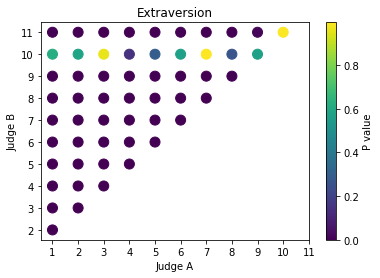

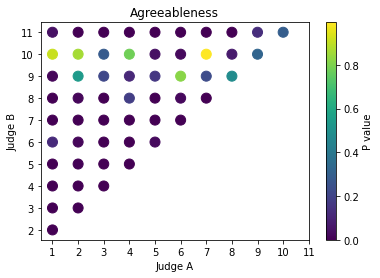

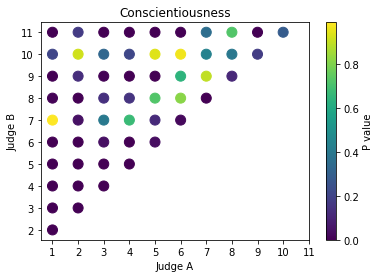

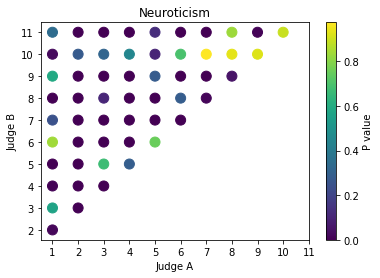

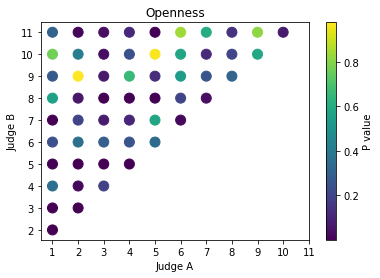

In [17]:
#Returns a list [JudgeA, JudgeB, and then one by one the correlation coef OR p value for each trait]
def SpearmanRankAllJudgesAllTraitsRorP(RhoORP, no10):
    if (RhoORP=='rho'):
        RorP = 0
    if (RhoORP=='p'):
        RorP = 1
    listOfPairsAndRank = []
    i=0
    while (i<11):
        if ((no10==True) & (i==9)):
            i = i+1
        if (i<9):
            x = '0' + str(i+1)
        else:
            x = str(i+1)
        judgeA = np.array(printJudge(x))
        j = i + 1
        while (j<11):
            if ((no10==True) & (j==9)):
                j = j+1
            row =[]
            if (j<9):
                y = '0' + str(j+1)
            else:
                y = str(j+1)
            judgeB = np.array(printJudge(y))
            row.append(i+1)
            row.append(j+1)
            for k in range(1,6):
                row.append(scipy.stats.spearmanr(judgeA[:,k].tolist(), judgeB[:,k].tolist())[RorP])
            listOfPairsAndRank.append(row)
            j = j+1
        i = i+1
    return listOfPairsAndRank

def judgeSkewPlot():
    data = SpearmanRankAllJudgesAllTraitsRorP('p', False)

    display(Markdown('## Plots of P values (color)per combination of judges (axis)'))

    for i in range(1,6):
        d =  np.array(data)[:,i+1]
        pairs = list(zip(np.array(data)[:,0],np.array(data)[:,1]))
        stringPairs = list(map(lambda x: f'({x[0]}, {x[1]})', pairs))
        y1 = np.array(data)[:,0]
        y2 = np.array(data)[:,1]

        # fig, ax1 = plt.subplots(figsize=(8, 12))
        # ticks = range(len(stringPairs))
        # ax1.scatter(d, stringPairs, color='blue', label='Value')
        # ax1.set_xlabel('P Value')
        # ax1.set_yticks(ticks)
        # ax1.set_yticklabels(y1)
        # ax1.set_ylabel('Judge A', color='blue')
        # ax1.tick_params(axis='y', labelcolor='blue')
        # ax1.set_ylim(min(ticks), max(ticks)+1)
        # ax2 = ax1.twinx()
        # ax2.set_yticks(ticks)
        # ax2.set_yticklabels(y2)
        # ax2.set_ylabel('Judge B', color='red')
        # ax2.tick_params(axis='y', labelcolor='red')
        # plt.grid(True)
        # plt.show()

        # plt.figure(figsize=(8,12))
        # plt.scatter(d,stringPairs)
        # plt.xlabel('P value')
        # plt.ylabel('Pairs')
        # plt.grid(True)
        # plt.show()

        plt.scatter(np.array(data)[:,0], np.array(data)[:,1], c=d, cmap='viridis', s=100, alpha=1)
        cbar = plt.colorbar()
        cbar.set_label('P value')
        plt.xticks(np.arange(1,12))
        plt.yticks(np.arange(2,12))
        plt.title(bigFive[i-1])
        plt.xlabel('Judge A')
        plt.ylabel('Judge B')
        plt.show()

        # fig = plt.figure()
        # ax = fig.add_subplot(111, projection='3d')
        # ax.scatter(np.array(data)[:,0], np.array(data)[:,1], d)
        # ax.set_xlabel('Judge A')
        # ax.set_ylabel('Judge B')
        # ax.set_zlabel('P value')
        # plt.show()

# judgeSkewPlot()


In [33]:
#Bonferroni Correction on Spearman Rank of judge pairs

#Parameter - method - 'bonferroni' , 'sidak', 'fdr_bh', 
def spearmanJudgesCorrection(method,returnInfo,no10):
    if (no10 == True):
        data = SpearmanRankAllJudgesAllTraitsRorP("p", True)
        corrected = np.zeros((45,7))
    else:   
        data = SpearmanRankAllJudgesAllTraitsRorP("p", False)
        corrected = np.zeros((55,7))
    
    corrected[:,0:2] = np.array(data)[:,0:2]
    corrected[:,0:2].astype(int)
    correctedAlphaBonferroni = statsmodels.stats.multitest.multipletests(np.array(data)[:,2], alpha=0.05, method=method, maxiter=1, is_sorted=False, returnsorted=False)[3]
    correctedAlphaSidak = statsmodels.stats.multitest.multipletests(np.array(data)[:,2], alpha=0.05, method=method, maxiter=1, is_sorted=False, returnsorted=False)[2]
    if ((returnInfo == 'alpha') & (method=='bonferroni')):
        # print( "Bonferroni alpha: ")
        return correctedAlphaBonferroni
    if ((returnInfo == 'alpha') & (method=='sidak')):
        # print( "Sidak alpha: ")
        return correctedAlphaSidak
    for i in range(2,7):
        corrected[:,i] = (statsmodels.stats.multitest.multipletests(np.array(data)[:,i], alpha=0.05, method=method, maxiter=1, is_sorted=False, returnsorted=False)[1])
    return corrected

def spearmanJudgesCorrectionTable(method, no10):
    display(Markdown(f'### {method} Correction p values of Spearman Rank between Genders For each judge'))
    corrected = spearmanJudgesCorrection(method,'P Values', no10)
    correctionTable = pd.DataFrame(corrected, columns= np.concatenate((['JudgeA', 'JudgeB'],bigFive),axis=0))
    correctionTable['JudgeA'] = correctionTable['JudgeA'].astype(int)
    correctionTable['JudgeB'] = correctionTable['JudgeB'].astype(int)
    correctionTable.index = range(1, len(corrected) + 1)
    display (correctionTable)


In [34]:
## T tests over the Spearman p values

def tTestPvalues():
    resultPvalue=[]
    import itertools
    data = SpearmanRankAllJudgesAllTraitsRorP('p', True)
    tStatistic =[]
    pValue = []

    # how can i do it since it takes two arrays and i only have 1 array of the p values
    for i in range(1,6):
        d =  np.array(data)[:,i+1]
        pairs = list(itertools.combinations(d, 2))
        first_elements = [pair[0] for pair in pairs]
        second_elements = [pair[1] for pair in pairs]
        t, p = scipy.stats.ttest_ind(second_elements, first_elements)
        tStatistic.append(t)
        pValue.append(p)
    display(Markdown('## T test of the p values from spearman'))
    resultPvalue.append(pValue)
    df = pd.DataFrame(resultPvalue, columns=bigFive)
    df.index = ['P value']
    display (df)
    # return (resultPvalue)


In [35]:
# Table of Average Spearman rank per trait

def SpearmanAverageTable(averageType, no10):
    if (no10 == True):
        data_dict = SpearmanRankAllJudgesAllTraits(True)
        columns = np.concatenate((['JudgeA', 'JudgeB'],bigFive),axis=0)
        data = pd.DataFrame(data_dict, columns=columns) 
        # data.index = range(1, len(dfSpearman) + 1)
    else:
        data_dict = SpearmanRankAllJudgesAllTraits(False)
        columns = np.concatenate((['JudgeA', 'JudgeB'],bigFive),axis=0)
        data = pd.DataFrame(data_dict, columns=columns) 
        # data.index = range(1, len(dfSpearman) + 1)  
    if (no10==True):
        note = "Excluding Judge 10"
    else: 
        note = ''
    averagesPerTrait = []
    for trait in bigFive:
        # print(data[trait])
        if (averageType == "Mode"):
            averagesPerTrait.append(scipy.stats.mode(data[trait].tolist(),axis=0)[0][0])
        if (averageType == "Mean"):          
            averagesPerTrait.append(data[trait].mean())
        if (averageType == "Median"):    
            df = pd.DataFrame(data[trait].tolist(),columns=['rho','p'])
            averagesPerTrait.append((df['rho'].median(),df['p'].median()))
    dfAverages = pd.DataFrame(averagesPerTrait,columns=['Spearman Rank','P value'])
    dfAverages.index = bigFive
    display(Markdown(f'#### {averageType} Average Spearman Rank per Trait (Rank & P-value) {note}'))
    display(dfAverages)
    return(dfAverages)

# SpearmanAverageTable('Median', True)
# SpearmanAverageTable('Mean', True)
# SpearmanAverageTable('Mode', False)
# SpearmanAverageTable('Mode', True)


In [36]:
# Function running the different spearman averages for Judge Agreement & returning conclusions

# x = SpearmanAverageTable('Mean',False)
# print(np.array(x))
# print(x['P value'][bigFive[2]])

        
def judgeAgreementResults(averageMethod, no10, alpha):
    if (no10== True):
        info = "Excluding Judge 10"
    else:
        info = "Including Judge 10"
    data = SpearmanAverageTable(averageMethod, no10)
    display(Markdown(f'#### Statistical Significance for {averageMethod} Spearman Rank {info}'))
    for i in range (5):
        value = data['P value'][bigFive[i]]
        sig = ''
        if (value > alpha):
            sig = 'NOT'
        print(bigFive[i], " - ", sig, " Statistically Significant")


# judgeAgreementResults('Mean',False,0.05)
# judgeAgreementResults('Median',False,0.05)


In [37]:
def SpearmanAverageTableCorrection(method, averageType,no10):
    meanAveragesPerTrait = []
    medianAveragesPerTrait = []
    for i in range(2,7):   
        x = spearmanJudgesCorrection(method, 'P Values', no10)
        meanAveragesPerTrait.append(x[:,i].mean())
        df = pd.DataFrame(x[:,i],columns=['p'])
        medianAveragesPerTrait.append(df['p'].median())
    if (averageType == 'mean'):
        averagesPerTrait = meanAveragesPerTrait
    if (averageType == 'median'):
        averagesPerTrait = medianAveragesPerTrait
    dfAverages = pd.DataFrame(averagesPerTrait,columns=['P-value'])
    dfAverages.index = bigFive
    display(Markdown(f'## Post {method} Average Spearman Rank per Trait (Rank & P-value)'))
    display(dfAverages)
    return dfAverages


# SpearmanAverageTableCorrection('bonferroni','mean',False)
# SpearmanAverageTableCorrection('bonferroni','median')
# SpearmanAverageTableCorrection('sidak','mean')
# SpearmanAverageTableCorrection('sidak','median')



In [38]:
def judgeAgreementResultsFDR(averageMethod, no10, alpha):
    if (no10== True):
        info = "Excluding Judge 10"
    else:
        info = "Including Judge 10"
    data = SpearmanAverageTableCorrection('fdr_bh',averageMethod, no10)
    display(Markdown(f'#### Statistical Significance for {averageMethod} Spearman Rank {info}'))
    for i in range (5):
        # print(data)
        value = data['P-value'][bigFive[i]]
        sig = ''
        if (value > alpha):
            sig = 'NOT'
        print(bigFive[i], " - ", sig, " Statistically Significant")


# judgeAgreementResultsFDR('median', False, 0.05)

## Spearman Brown Correlation

* Evaluates test reliability
* used when the length of a test is changed and you want to see if reliability has increased? -> original test having 10 questions and new having 15.
* shows an estimate of how much the test reliability will change if the number of items/questions in the test is altered.
<br>
<br>
* In this case
    * how the number of judges affects the reliability

* Parameters
    * n - new test Length - new length/no of questions
    * R old - spearman rank rho

* SPLIT HALF RELIABILITY
    * Reliability Coefficient (R)
        * Calculate correlation between two halves 
            * female vs male? or judges?
                * the two halves must be even.
    * Take a random sample of half of the items & run analysis between the two halves?

* Spearman Brown formula 
    * Rnew = 2R/1+R


* So high correlation = high reliability.
* Usually over 0.7 it is considered good.

In [41]:
# Getting the spearman brown for a specific trait for a specific number of judges
# If no10 is true - then Judge 10 will be excluded and the frequency is 10
#Using the mean of rho values for each trait
def spearmanBrown(trait, numberOfjudges,no10):
    old = np.mean(SpearmanRankAllJudgesOneTraitRho(trait,no10))
    return (old, (numberOfjudges * old / (1 + (numberOfjudges - 1) * old)))

def SpearmanBrownTable(no10):
    if (no10==False):
        number = 11
    else:
        number = 10
    spearmanBrownPerTrait = []
    for trait in range(1,6):       
        spearmanBrownPerTrait.append(spearmanBrown(trait,number,no10))
    # print(spearmanBrownPerTrait)
    dfBrown = pd.DataFrame(spearmanBrownPerTrait, columns = ['Correlation', 'Spearman Brown'])
    dfBrown.index = bigFive
    display(Markdown('#### Spearman Brown per Trait (Correlation (Reliability old) & Spearman Brown (new))'))
    display(dfBrown)
    return(dfBrown)

#Using the median of rho values for each trait
def spearmanBrownMedian(trait, numberOfjudges,no10):
    old = np.median(SpearmanRankAllJudgesOneTraitRho(trait,no10))
    return (old, (numberOfjudges * old / (1 + (numberOfjudges - 1) * old)))


def SpearmanBrownTableMedian(no10):
    if (no10==False):
        number = 11
    else:
        number = 10
    spearmanBrownPerTrait = []
    for trait in range(1,6):       
        spearmanBrownPerTrait.append(spearmanBrownMedian(trait,number,no10))
    # print(spearmanBrownPerTrait)
    dfBrown = pd.DataFrame(spearmanBrownPerTrait, columns = ['Correlation', 'Spearman Brown'])
    dfBrown.index = bigFive
    display(Markdown('#### Spearman Brown per Trait (Correlation (Reliability old) & Spearman Brown (new))'))
    display(dfBrown)

# SpearmanBrownTable(False)
# SpearmanBrownTable(True)
# SpearmanBrownTableMedian(False)


def SpearmanBrownResults(no10):
    data = SpearmanBrownTable(no10)
    values = data['Spearman Brown']
    rho = data['Correlation']
    for trait in bigFive:
        if (values[trait] > 0.7):
            print(trait, ' is GOOD \n     rho:', rho[trait])
        if (values[trait] > 0.5):
            print(trait, ' is FAIR \n     rho:', rho[trait])
        else:
            print(trait, ' is BAD \n     rho:', rho[trait])


## CORRELATION BETWEEN GENDERS

In [42]:
#Pearson Correlation Histograms

#ALL RECORDINGS FROM ALL JUDGES (INCLUDING DUPLICATES) FOR A GENDER
def allJudgesOneGender(gender, no10):
    total = splitPerGender(gender, judge1)
    i=1
    while (i<11):
        if (no10):
            if (i==9):
                i=i+1
        if (i<9):
            x = '0' + str(i+1)
        else:
            x = str(i+1)
        total = np.concatenate((total, splitPerGender(gender,np.array(printJudge(x)))), axis=0)
        i=i+1
    return total
    
# print(allJudgesOneGender('F',True))

### PER GENDER



In [43]:
#Pearson Correlation Coefficients Per trait per GENDER FOR THE FIRST 1507 NUMBER OF MALE INPUTS

def corrPerTraitBetweenGenders():
    listOfCoefficients = []
    i=1
    while i <6:
        listOfCoefficients.append(np.corrcoef(np.array(allJudgesOneGender('M',False)[:1507,i]).tolist(), np.array(allJudgesOneGender('F',False)[:,i]).tolist())[0:1][0][1])
        i = i + 1
    return (listOfCoefficients)

# print(corrPerTraitBetweenGenders())


In [44]:
# display(Markdown('# Comparisons between judges focusing on a specific gender'))

### Correlation between 55 unique combinations of judges for a specific trait
### FOR ONE GENDER

### Pearson Correlation per trait for only one gender - over all judges

In [45]:
#Correlation between judges for a trait only for ONE specific gender

def corrAllJudgesOneGenderOneTrait(trait, gender):
    listOfCoefficients = []
    listOfPairs = []
    for i in range(11):
        if (i<9):
            x = '0' + str(i+1)
        else:
            x = str(i+1)
        judgeA = splitPerGender(gender,np.array(printJudge(x)))
        for j in range(i+1,11):
            if (j<9):
                y = '0' + str(j+1)
            else:
                y = str(j+1)
            judgeB = splitPerGender(gender,np.array(printJudge(y)))
            # listOfPairs.append((i+1,j+1))
            listOfCoefficients.append(np.corrcoef(judgeA[:,trait].tolist(), judgeB[:,trait].tolist())[0:1][0][1])
    # print(listOfPairs)
    return (listOfCoefficients)

# corrAllJudgesOneGenderOneTrait(2,'M').shape


In [46]:
def corrAllJudgesOneGenderAllTraitWithP(gender, onlyP):
    listOfCoefficients = []
    listOfPairs = []
    listOfPairsAndCorr = []
    listOfPairsAndPs = []
    for i in range(11):
        if (i<9):
            x = '0' + str(i+1)
        else:
            x = str(i+1)
        judgeA = splitPerGender(gender,np.array(printJudge(x)))
        for j in range(i+1,11):
            row = []
            row2 = []
            if (j<9):
                y = '0' + str(j+1)
            else:
                y = str(j+1)
            judgeB = splitPerGender(gender,np.array(printJudge(y)))
            # listOfPairs.append((i+1,j+1))
            row.append(i+1)
            row2.append(i+1)
            row.append(j+1)
            row2.append(j+1)
            for k in range(1,6):
                listOfCoefficients.append(scipy.stats.pearsonr(judgeA[:,k].tolist(), judgeB[:,k].tolist()))
                row2.append(scipy.stats.pearsonr(judgeA[:,k].tolist(), judgeB[:,k].tolist())[1])
                row.append(np.array(scipy.stats.pearsonr(judgeA[:,k].tolist(), judgeB[:,k].tolist())))
            listOfPairsAndPs.append(row2)
            listOfPairsAndCorr.append(row)
    # print(listOfPairs)
    # return (listOfCoefficients)
    if (onlyP==True):
        return listOfPairsAndPs
    else:
        return listOfPairsAndCorr

# np.array(corrAllJudgesOneGenderAllTraitWithP('F',True)).shape


In [47]:
def SpearmanRankAllJudgesAllTraitsPerGender(gender):
    listOfPairsAndRank = []
    for i in range(11):
        if (i<9):
            x = '0' + str(i+1)
        else:
            x = str(i+1)
        judgeA = splitPerGender(gender,np.array(printJudge(x)))
        for j in range(i+1,11):
            row =[]
            if (j<9):
                y = '0' + str(j+1)
            else:
                y = str(j+1)
            judgeB = splitPerGender(gender,np.array(printJudge(y)))
            row.append(i+1)
            row.append(j+1)
            for k in range(1,6):
                row.append(scipy.stats.spearmanr(judgeA[:,k].tolist(), judgeB[:,k].tolist()))
            listOfPairsAndRank.append(row)
    return listOfPairsAndRank

Correlation between the judges ONLY FOR ONE GENDER for a specific trait

In [48]:
#HISTOGRAMS FOR EACH TRAIT FOR THE FREQUENCY OF THE CORRELATIONS OF ALL 55 COMBINATIONS OF JUDGES
####FEMALE

# fig, axs = plt.subplots(5, 1, figsize=(7, 30))
# axs = axs.flatten()
# for i in range(1,6):
#     axs[i-1].hist(corrAllJudgesOneGenderOneTrait(i,'F'), bins=90, range=(-0.25,0.8), color='blue', edgecolor='black', rwidth=0.8, label=f'All correlations between judges {bigFive[i-1]}')
#     axs[i-1].set_title(f'Frequency against Correlation Coefficient between judges for {bigFive[i-1]}', fontsize=10)
#     axs[i-1].set_xlabel('Correlation Coefficient between judges', fontsize=10)
#     axs[i-1].set_ylabel('Frequency of a specific correlation', fontsize=10)
# # axs[5].axis('off')
# plt.tight_layout(pad=0.4, w_pad=0.5, h_pad=1.0)
# plt.figure()

In [49]:
## TABLE FOR EACH TRAIT FOR THE CORRELATION OF ALL 55 JUDGES FOR FEMALE ONLY


dataDictFemalePearson = corrAllJudgesOneGenderAllTraitWithP('F',False)
dataDictMalePearson = corrAllJudgesOneGenderAllTraitWithP('M',False)

columns = np.concatenate((['JudgeA', 'JudgeB'],bigFive),axis=0)
dfFemalePearson = pd.DataFrame(dataDictFemalePearson, columns=columns) 
dfFemalePearson.index = range(1, len(dfFemalePearson) + 1)

dfMalePearson = pd.DataFrame(dataDictMalePearson, columns=columns) 
dfMalePearson.index = range(1, len(dfMalePearson) + 1)

def femaleOnlyPearson():
    display(Markdown('## Pearson Correlations For Female For each Trait in Coefficient, P-value pairs'))
    display(dfFemalePearson)

def maleOnlyPearson():
    display(Markdown('## Pearson Correlations For Male For each Trait in Coefficient, P-value pairs'))
    display(dfMalePearson)



In [50]:
# Table of Average pearson correlation per trait


def oneGenderAveragePearson(gender):
    averagesPerTraitMale = []
    averagesPerTraitFemale = []
    for trait in bigFive:       
        averagesPerTraitMale.append(dfMalePearson[trait].mean())
        averagesPerTraitFemale.append(dfFemalePearson[trait].mean())
    if (gender=='male'):
        data = averagesPerTraitMale
    else: 
        data = averagesPerTraitFemale
    dfAverage = pd.DataFrame(data,columns=['Correlation Coefficient','P-value'])
    dfAverage.index = bigFive
    display(Markdown(f'## Average Pearson Correlations For {gender} For each Trait in Coefficient, P-value pairs'))
    display (dfAverage)


In [51]:
#HISTOGRAMS FOR EACH TRAIT FOR THE FREQUENCY OF THE CORRELATIONS OF ALL 55 COMBINATIONS OF JUDGES
####MALE

# fig, axs = plt.subplots(5, 1, figsize=(7, 30))
# axs = axs.flatten()
# for i in range(1,6):
#     axs[i-1].hist(corrAllJudgesOneGenderOneTrait(i,'M'), bins=90, range=(-0.25,0.5), color='green', edgecolor='black', rwidth=0.8, label=f'All correlations between judges {bigFive[i-1]}')
#     axs[i-1].set_title(f'Frequency against Correlation Coefficient between judges for {bigFive[i-1]}', fontsize=10)
#     axs[i-1].set_xlabel('Correlation Coefficient between judges', fontsize=10)
#     axs[i-1].set_ylabel('Frequency of a specific correlation', fontsize=10)
# # axs[5].axis('off')
# plt.tight_layout(pad=0.4, w_pad=0.5, h_pad=1.0)
# plt.figure()

### Spearman Rank per trait for only one gender - over all judges

In [52]:
## TABLE FOR EACH TRAIT FOR THE SPEARMAN RANK OF ALL 55 JUDGES FOR FEMALE ONLY

def oneGenderOnlySpearman(gender):
    columns = np.concatenate((['JudgeA', 'JudgeB'],bigFive),axis=0)
    if (gender=='male'):
        dfGender  = pd.DataFrame(SpearmanRankAllJudgesAllTraitsPerGender('M'), columns=columns) 
    if (gender=='female'):
        dfGender = pd.DataFrame(SpearmanRankAllJudgesAllTraitsPerGender('F'), columns=columns) 
    print(len(dfGender))
    dfGender.index = range(1, len(dfGender) + 1)
    display(Markdown(f'## Spearman Rank For {gender} For each Trait in Coefficient, P-value pairs'))
    display(dfGender)
    return dfGender

# oneGenderOnlySpearman('female')
# oneGenderOnlySpearman('male')


In [53]:
# print(SpearmanRankAllJudgesAllTraitsRorP("p"))
# print(dataDictFemale)

# def femaleOnlySpearmanBonferroni():
#     data = pd.DataFrame(corrAllJudgesOneGenderAllTraitWithP('F',True), columns=columns) 
#     corrected = np.zeros((55,7))
#     corrected[:,0:2] = np.array(data)[:,0:2]
#     corrected[:,0:2].astype(int)
#     for i in range(2,7):
#         corrected[:,i] = (statsmodels.stats.multitest.multipletests(np.array(data)[:,i], alpha=0.05, method='bonferroni', maxiter=1, is_sorted=False, returnsorted=False)[1])
#     # dfFemale.index = range(1, len(dfFemale) + 1)
#     # display(Markdown('## Spearman Rank For Female For each Trait in Coefficient, P-value pairs'))
#     # display(dfFemale)
#     print(corrected.shape)
#     table = pd.DataFrame(corrected, columns=judges)
#     table.index = bigFive
#     display (table)

# femaleOnlySpearmanBonferroni()

In [54]:
# Table of Average of the spearman rank per trait

def maleOnlyAverageSpearman(averageType):
    columns = np.concatenate((['JudgeA', 'JudgeB'],bigFive),axis=0)
    dfMale  = pd.DataFrame(SpearmanRankAllJudgesAllTraitsPerGender('M'), columns=columns) 
    averagesPerTraitMale = []
    for trait in bigFive:   
        if (averageType=="Mean"):
            df = pd.DataFrame(dfMale[trait].tolist(),columns=['rho','p'])
            averagesPerTraitMale.append((df['rho'].median(),df['p'].mean()))
        if (averageType=="Mode"):
            averagesPerTraitMale.append(scipy.stats.mode(dfMale[trait].tolist(),axis=0)[0][0])
        if (averageType=="Median"):
            df = pd.DataFrame(dfMale[trait].tolist(),columns=['rho','p'])
            averagesPerTraitMale.append((df['rho'].median(),df['p'].median()))
    dfAveragesMale = pd.DataFrame(averagesPerTraitMale,columns=['Spearman Rho','P-value'])
    dfAveragesMale.index = bigFive
    display(Markdown(f'#### {averageType} Average Spearman Rank For Male For each Trait in Coefficient, P-value pairs'))
    display (dfAveragesMale)
    return dfAveragesMale


def femaleOnlyAverageSpearman(averageType):
    columns = np.concatenate((['JudgeA', 'JudgeB'],bigFive),axis=0)
    dfFemale  = pd.DataFrame(SpearmanRankAllJudgesAllTraitsPerGender('F'), columns=columns) 
    averagesPerTraitFemale = []
    for trait in bigFive:   
        if (averageType=="Mean"):
            df = pd.DataFrame(dfFemale[trait].tolist(),columns=['rho','p'])
            averagesPerTraitFemale.append((df['rho'].median(),df['p'].mean()))
        if (averageType=="Mode"):
             averagesPerTraitFemale.append(scipy.stats.mode(dfFemale[trait].tolist(),axis=0)[0][0])
        if (averageType=="Median"):
            df = pd.DataFrame(dfFemale[trait].tolist(),columns=['rho','p'])
            averagesPerTraitFemale.append((df['rho'].median(),df['p'].median()))
        # if (averageType=="Median"):
            #  averagesPerTraitFemale.append(statistics.median(dfFemale[trait].tolist()))
    dfAveragesFemale = pd.DataFrame(averagesPerTraitFemale,columns=['Spearman Rho','P-value'])
    dfAveragesFemale.index = bigFive
    display(Markdown(f'#### {averageType} Average Spearman Rank For Female For each Trait in Coefficient, P-value pairs'))
    display(dfAveragesFemale)
    return dfAveragesFemale

def oneGenderAverageSpearmanResults(averageType,gender,alpha):
    if (gender == 'male'):
        data = maleOnlyAverageSpearman(averageType)
    else:
        data = femaleOnlyAverageSpearman(averageType)
    display(Markdown(f'#### Statistical Significance for {averageType} Spearman Rank Only for {gender}'))
    for i in range (5):
        value = data['P-value'][bigFive[i]]
        sig = ''
        if (value > alpha):
            sig = 'NOT'
        print(bigFive[i], " - ", sig, " Statistically Significant")
    
# oneGenderAverageSpearmanResults('Median', 'male', 0.05)

Correlation per trait - between genders of each judge
* how is this judge stereotyping?

In [55]:
# display(Markdown('# Comparisons between gender using t-tests'))

## T test
* DIFFERENT SIZES OF THE TWO SAMPLES (female & female) BUT same variance
* Two/Independent Sample T-test
    * checks whether the unknown population means of a given pair of groups are equal - determine if the samples are different from each other
    * different people providing scores for each group
    * Results:
        * t-statistic -> larger t-statistic = greater difference between the groups
        * p-value: if <0.05 then reject null hypothesis - there is a difference between the mean of male & female
  

In [56]:
# T test Table for every judge individually
data = []
for i in range(11):
    judgeTraits=[]
    if (i<9):
        x = '0' + str(i+1)
    else:
        x = str(i+1)
    judge = np.array(printJudge(x))
    for j in range(1,6):
        tStatistic, pValue = scipy.stats.ttest_ind(a=splitPerGender('F',judge)[:,j].tolist(), b=splitPerGender('M',judge)[:,j].tolist(), equal_var=True)
        result = [tStatistic, pValue]
        judgeTraits.append(result)
    data.append(judgeTraits)

dfTtest = pd.DataFrame(data,columns=bigFive)

def tTestIndividualJudgeTable():
    dfTtest = pd.DataFrame(data,columns=bigFive)
    dfTtest.index = ['Judge1', 'Judge2', 'Judge3', 'Judge4','Judge5', 'Judge6','Judge7', 'Judge8','Judge9', 'Judge10','Judge11']
    display(Markdown('## T-test results between Genders For each judge individually per Trait in t-statistic, P-value pairs'))
    display (dfTtest)



In [57]:
# Effect size - how meaningful the relationship between variables or the difference between group is.

from math import sqrt
def cohensD(a,b):
    return (statistics.mean(a) - statistics.mean(b)) / (sqrt((statistics.stdev(a) ** 2 + statistics.stdev(b) ** 2) / 2))

data = []
for i in range(11):
    judgeTraits=[]
    if (i<9):
        x = '0' + str(i+1)
    else:
        x = str(i+1)
    judge = np.array(printJudge(x))
    for j in range(1,6):
        judgeTraits.append(cohensD(splitPerGender('F',judge)[:,j].tolist(), splitPerGender('M',judge)[:,j].tolist()))
    data.append(judgeTraits)

# print(np.array(data).shape)

dfCohens = pd.DataFrame(data,columns=bigFive)
dfCohens.index = ['Judge1', 'Judge2', 'Judge3', 'Judge4','Judge5', 'Judge6','Judge7', 'Judge8','Judge9', 'Judge10','Judge11']
# display(Markdown('## Cohen\'s D results between Genders For each judge individually per Trait in t-statistic, P-value pairs'))
# display (dfCohens)


TABLE OF T TEST VALUES FOR WHOLE DATA OF MALE VS FEMALE INCLUDING DUPLICATE
* CLIPS FROM ALL JUDGES
* Judge independent


In [58]:
#TABLE OF T TEST VALUES FOR WHOLE DATA OF MALE VS FEMALE INCLUDING DUPLICATE CLIPS FROM ALL JUDGES

def tTestAllMalevsAllFemaleCorrection(method,no10):
    data = tTestAllMalevsAllFemale(no10)['P-value']
    if (method=='bonferroni'):
        alphaB= (statsmodels.stats.multitest.multipletests(data, alpha=0.05, method=method, maxiter=1, is_sorted=False, returnsorted=False)[3])
        return alphaB
    if (method=='sidak'):
        alphaS= (statsmodels.stats.multitest.multipletests(data, alpha=0.05, method=method, maxiter=1, is_sorted=False, returnsorted=False)[2])
        return alphaS

def tTestAllMalevsAllFemale(no10):
    data=[]
    for j in range(1,6):
        data.append(scipy.stats.ttest_ind(a=allJudgesOneGender('F',no10)[:,j].tolist(), b=allJudgesOneGender('M',no10)[:,j].tolist(), equal_var=True))
    df = pd.DataFrame(data,columns=['T-statistic','P-value'])
    df.index = bigFive
    display(Markdown('### T-test results between Genders For each Trait using all judges\' data in t-statistic, P-value pairs'))
    display (df)
    return df






In [59]:
def tTestAllDataResults(no10, p):
    if (no10== True):
        info = "Excluding Judge 10"
    else:
        info = "Including Judge 10"
    data = tTestAllMalevsAllFemale(no10)
    display(Markdown(f'#### Statistical Significance for t-test over all male vs all female {info}'))
    for i in range (5):
        value = data['P-value'][bigFive[i]]
        sig = ''
        if (value > p):
            sig = 'NOT'
        print(bigFive[i], " - ", sig, " Statistically Significant")




# tTestAllDataResults(False, 0.05)

### CORRECTION

- Used to account for inflated Type I error 
    - the higher the chance for a false positive
- Familywise Error Rate
    - the probability of 1+ Type I errors in a set of comparisons.

#### Bonferroni
- Type of multiple comparison test used in statistical analysis. 
- A statistical test used to reduce instances of false positives
- The p value of each test should be equal to its aplha divided by the number of tests.  
- Controls the probebility of at least making one false conclusion
- Most common use: If I have a list of t-tests and a significant result for even one of them that rejects the null hypothesis
    - Use Bonferroni correction

statsmodels.stats.multitest.multipletests(pvals, alpha=0.05, method='hs', maxiter=1, is_sorted=False, returnsorted=False)
- pvals - 1D array of p values
- method = 'bonferroni'
        

#### Sidak
- A simple method of controlling family-wise error rate
- More powerful that Bonferroni
- Assumes each comparison is independent from the others
- considers the number of tests performed and then adjusts the alpha.

#### False discovery rate correction
- Alternative to Bonferroni
- Controls for a low proportion of false positives
- Methods
    - Benjamini-Hochberg
        - controls for the expected proprotion of false discoveries among all disoveries 
    - Benjamini-Yekutieli
        - Stricted correction BH when the tests are dependent or have strong positive correlation


In [60]:
# CORRECTION ON T TESTS PER JUDGE (M vs F)
# TO USE FOR tTestIndividualJudgeTable p values

#PARAMETERS: 'bonferroni', 'sidak', 'fdr_bh','fdr_by'
def genderComparisonperJudgeCorrection(method, returnInfo, no10):
    if (no10 == True):
        info = "Excluding Judge 10"
    else:
        info = "Including Judge 10"
    judgeNo = 0
    data = []
    pValues = []
    while (judgeNo<11):
        judgeP=[]
        judgeTraits=[]
        if (i<9):
            x = '0' + str(i+1)
        else:
            x = str(i+1)
        judge = np.array(printJudge(x))
        for j in range(1,6):
            tStatistic, pValue = scipy.stats.ttest_ind(a=splitPerGender('F',judge)[:,j].tolist(), b=splitPerGender('M',judge)[:,j].tolist(), equal_var=True)
            result = [tStatistic, pValue]
            judgeP.append(pValue)
            judgeTraits.append(result)
        data.append(judgeTraits)
        pValues.append(judgeP)
        if ((no10 == True) & (judgeNo == 9)):
            judgeNo = judgeNo + 2
        else:
            judgeNo = judgeNo + 1

    dfTtest = pd.DataFrame(data,columns=bigFive)
    pValueTotal = pd.DataFrame(pValues,columns=bigFive)

    display(Markdown(f'### {method} Correction p values of T-test results between Genders For each judge {info}'))
    corrected = []
    if ((returnInfo == 'alpha') & (method=='bonferroni')):
        alphaB = (statsmodels.stats.multitest.multipletests(pValueTotal[bigFive[1]], alpha=0.05, method=method, maxiter=1, is_sorted=False, returnsorted=False)[3])
        return alphaB
    if ((returnInfo == 'alpha') & (method=='sidak')):
        alphaS = (statsmodels.stats.multitest.multipletests(pValueTotal[bigFive[1]], alpha=0.05, method=method, maxiter=1, is_sorted=False, returnsorted=False)[2])
        return alphaS
    for trait in bigFive:
        corrected.append(statsmodels.stats.multitest.multipletests(pValueTotal[trait], alpha=0.05, method=method, maxiter=1, is_sorted=False, returnsorted=False)[1])
    
    correctionTable = pd.DataFrame(corrected, columns=judges)
    correctionTable.index = bigFive
    display (correctionTable)


# genderComparisonperJudgeCorrection('bonferroni', 'alpha', False)


TABLE OF T TEST VALUES FOR AVERAGE CLIPS OF MALE VS FEMALE 
* AVERAGE PER CLIP OVER ALL JUDGES
* Judge independent

In [61]:
#TABLE OF T TEST VALUES FOR MEAN PER CLIP OF MALE VS FEMALE

def tTestAveragePerClipGender(averageType):
    if (averageType=="Mean"):
        averageClips = meanScoresPerClip()
    if (averageType=="Mode"):
        averageClips = modeScoresPerClip()
    if (averageType=="Median"):
        averageClips = medianScoresPerClip()
    data=[]
    for j in range(1,6):
        female = averageClips[np.where(np.array(metadata)[:,2] == 'F')[0]]
        male = averageClips[np.where(np.array(metadata)[:,2] == 'M')[0]]
        data.append(scipy.stats.ttest_ind(a=female[:,j].tolist(), b=male[:,j].tolist(), equal_var=True))

    df = pd.DataFrame(data,columns=['T-statistic','P-value'])
    df.index = bigFive
    display(Markdown(f'### T-test results between Genders For each Trait using {averageType} per clip in t-statistic, P-value pairs'))
    display (df)
    return df

# tTestAveragePerClipGender("Mean")


def tTestAveragePerClipGenderCorrection(method):
    data = tTestAveragePerClipGender('Mean')['P-value']
    # ??????
    if (method=='bonferroni'):
        alphaB= (statsmodels.stats.multitest.multipletests(data, alpha=0.05, method=method, maxiter=1, is_sorted=False, returnsorted=False)[3])
        return alphaB
    if (method=='sidak'):
        alphaS= (statsmodels.stats.multitest.multipletests(data, alpha=0.05, method=method, maxiter=1, is_sorted=False, returnsorted=False)[2])
        return alphaS

def tTestAveragePerClipGenderResults(averageType,p):
    data = tTestAveragePerClipGender(averageType)
    display(Markdown(f'#### Statistical Significance for t-test of  {averageType} average per clip'))
    for i in range (5):
        value = data['P-value'][bigFive[i]]
        sig = ''
        if (value > p):
            sig = 'NOT'
        print(bigFive[i], " - ", sig, " Statistically Significant")


# tTestAveragePerClipGenderResults('Mean',0.05)

In [62]:
#Correlation For per trait between the genders of each judge?????

#Mean female & mean male for one judge
def meanGenderScoresPerJudge(judge):
    result={}
    clipIDsF = splitPerGender('F',judge)[:,0]
    clipIDsM = splitPerGender('M',judge)[:,0]
    fScores= splitPerGender('F', judge)[:,1:]
    mScores=splitPerGender('M', judge)[:,1:]
    meanScoreM = np.mean(mScores, axis=0)
    meanScoreF = np.mean(fScores, axis=0)
    result['F'] = meanScoreF
    result['M'] = meanScoreM
    return (result)

# print(meanGenderScoresPerJudge(judge1))

#correlation coefficient for one judge, between male and female.
#for 
def corrPerTraitBetweenGendersOnejudge(judge):
    femaleScores = meanGenderScoresPerJudge(judge)['F']
    maleScores = meanGenderScoresPerJudge(judge)['M']
    # print(femaleScores)
    # print(maleScores)
    # print(np.corrcoef(np.array(femaleScores).tolist(), np.array(maleScores).tolist()))
    # female = splitPerGender('F',judge)
    # male =splitPerGender('M',judge)
    listOfCoefficients = []
    i=1
    while i <6:
        listOfCoefficients.append(np.corrcoef(femaleScores.tolist(), maleScores.tolist())[0:1][0][1])
        i = i + 1
    return (listOfCoefficients)

# print(corrPerTraitBetweenGendersOnejudge(judge1))

# print(splitPerGender('F',judge1)[:,1:])



In [63]:


def boxPlotAveragePerClipGender(averageType, no10):
    display(Markdown('## Plot with average per clip for female vs male per trait'))
    
    for i in range(1,6):
        display(Markdown(f'### {bigFive[i-1]}'))
        if (averageType=='median'):
            dfF = np.array(medianScoresPerClipGender('F',no10)[:,i].tolist())
            dfM = np.array(medianScoresPerClipGender('M',no10)[:,i].tolist())
        if (averageType=='mean'):
            dfF = np.array(meanScoresPerClipGender('F',no10)[:,i].tolist())
            dfM = np.array(meanScoresPerClipGender('M',no10)[:,i].tolist())
        # dfF = np.array(medianScoresPerClipGender('F')[:,i])
        # dfM = np.array(medianScoresPerClipGender('M')[:,i])
        colorsdfF = ['green'] * len(dfF)  # Assign green color to female
        colorsdfM = ['lightblue'] * len(dfM)  # Assign blue color to male
        combinedData = np.concatenate((dfF,dfM),axis=0)
        labels = ['Female'] * len(dfF) + ['Male'] * len(dfM)
        df = pd.DataFrame({'Scores': combinedData, 'Gender' : labels})
        box = sns.boxplot(x='Gender', y='Scores', hue='Gender',data=df, legend=False)
        plt.show()
        
        # plt.scatter(dfM,range(len(dfM)), color=colorsdfM, label='Male')
        # plt.scatter(dfF, range(len(dfF)), color=colorsdfF, label='Female')
        # plt.xlabel('Scores')
        # plt.ylabel('Count')
        # plt.legend()
        # plt.show()

# boxPlotAveragePerClipGender('median',False)